# Cookie Cats A/B Test: Power and Sample Size

**Questions:** Did the test have enough players to detect the effects we saw?
How many players would a future test need?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

plt.style.use("default")

df = pd.read_csv("../data/cookie_cats.csv")
df = df[df["sum_gamerounds"] < df["sum_gamerounds"].max()]

rates = df.groupby("version")[["retention_1", "retention_7"]].mean()
sizes = df["version"].value_counts()
power_calc = NormalIndPower()

print(rates.round(4))
print(sizes)

         retention_1  retention_7
version                          
gate_30       0.4482       0.1902
gate_40       0.4423       0.1820
version
gate_40    45489
gate_30    44699
Name: count, dtype: int64


In [2]:
power_rows = {}
for metric in ["retention_1", "retention_7"]:
    h = proportion_effectsize(rates.loc["gate_30", metric], rates.loc["gate_40", metric])
    achieved_power = power_calc.solve_power(effect_size=h,
                                            nobs1=sizes["gate_30"],
                                            ratio=sizes["gate_40"] / sizes["gate_30"],
                                            alpha=0.05)
    needed = power_calc.solve_power(effect_size=h, power=0.8, alpha=0.05, ratio=1)
    power_rows[metric] = {
        "effect_size_h": round(h, 4),
        "power_achieved": f"{achieved_power:.0%}",
        "players_needed_per_group_for_80%": int(np.ceil(needed)),
    }
pd.DataFrame(power_rows).T

,effect_size_h,power_achieved,players_needed_per_group_for_80%
retention_1,0.0119,43%,110814
retention_7,0.021,88%,35502


In [3]:
h_min = power_calc.solve_power(nobs1=sizes["gate_30"], power=0.8, alpha=0.05,
                               ratio=sizes["gate_40"] / sizes["gate_30"])

for metric in ["retention_1", "retention_7"]:
    base = rates.loc["gate_30", metric]
    drops = np.arange(0.0001, 0.03, 0.0001)                       # 0.01 to 3 points
    effect = proportion_effectsize(base, base - drops)
    mde = drops[np.argmax(effect >= h_min)]                         # first drop that reaches h_min
    print(f"{metric}: smallest detectable drop ≈ {mde * 100:.2f} percentage points")

retention_1: smallest detectable drop ≈ 0.93 percentage points
retention_7: smallest detectable drop ≈ 0.73 percentage points


In [4]:
base7 = rates.loc["gate_30", "retention_7"]
plan = []
for mde_pts in [0.25, 0.5, 1.0, 2.0]:
    h = proportion_effectsize(base7, base7 - mde_pts / 100)
    n = power_calc.solve_power(effect_size=h, power=0.8, alpha=0.05)
    plan.append({"detect a drop of (pts)": mde_pts, "players per group": int(np.ceil(n))})
plan = pd.DataFrame(plan)
plan

,detect a drop of (pts),players per group
0,0.25,384873
1,0.50,95727
2,1.00,23683
3,2.00,5794


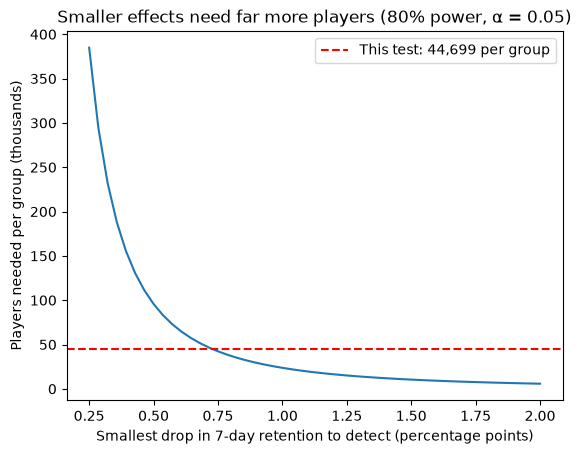

In [5]:
mde_grid = np.linspace(0.25, 2.0, 50)
n_grid = [power_calc.solve_power(effect_size=proportion_effectsize(base7, base7 - m / 100),
                                 power=0.8, alpha=0.05) for m in mde_grid]

plt.plot(mde_grid, np.array(n_grid) / 1000)
plt.axhline(sizes["gate_30"] / 1000, color="red", linestyle="--",
            label=f"This test: {sizes['gate_30']:,} per group")
plt.xlabel("Smallest drop in 7-day retention to detect (percentage points)")
plt.ylabel("Players needed per group (thousands)")
plt.title("Smaller effects need far more players (80% power, α = 0.05)")
plt.legend()
plt.savefig("../images/sample_size_curve.png", dpi=150, bbox_inches="tight")
plt.show()

## Power and sample size findings

| Metric | Observed drop | Power achieved | Smallest detectable drop | Players needed (80% power) |
|---|---|---|---|---|
| 1-day retention | 0.59 pts | **43%** | 0.93 pts | ~111,000 per group |
| 7-day retention | 0.82 pts | **88%** | 0.73 pts | ~35,500 per group |

- **7-day retention:** the test had 88% power, so the significant drop is trustworthy.
- **1-day retention:** only 43% power. The observed 0.6-point difference is smaller than what this
  test can reliably detect (0.93 pts), so "not significant" means **inconclusive**, not "no effect".
  Settling it would need ~111,000 players per group.
- **Planning rule:** halving the effect to detect roughly quadruples the sample needed
  (0.5 pts → ~96K per group; 0.25 pts → ~385K per group).